# Building and testing Models Here

## Imports


In [54]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.optimize import curve_fit

## Data

In [55]:
BASE_DIR = Path.cwd().parent
fig_dir = BASE_DIR / 'figures'

df_population = pd.read_csv(BASE_DIR / "input_data/input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(BASE_DIR / "input_data/input_data_GDP.csv", index_col=0)
df_steel = pd.read_csv(BASE_DIR / "input_data/input_data_production.csv", index_col=0)
df_energy_use = pd.read_excel(BASE_DIR / "input_data/final_energy_use.xlsx", index_col=0)

Cleaning the data in the next few blocks so thye can be used
For all of the forecast data (after 2024), everything is in 10 year increments, To make up for this, data was interpolated

In [56]:
# ─────────────────────────────────────────────────────────────────────────────
# GDP Dataframe
# ─────────────────────────────────────────────────────────────────────────────
df_gdp.index = df_gdp.index.astype(int) 
df_gdp = df_gdp.sort_index()
df_gdp = df_gdp.reindex(
    range(df_gdp.index.min(), df_gdp.index.max() + 1)
)

cols = ['gdp_ssp1','gdp_ssp2','gdp_ssp3','gdp_ssp4','gdp_ssp5']

df_gdp[cols] = (
    df_gdp[cols]
      .apply(pd.to_numeric, errors='coerce')
      .interpolate(method='cubic')
)

df_gdp= df_gdp.loc[df_gdp.index >= 1931]

In [57]:
# ─────────────────────────────────────────────────────────────────────────────
# Population Dataframe
# ─────────────────────────────────────────────────────────────────────────────
df_population.index = df_population.index.astype(int) 
df_population = df_population.sort_index()
df_population = df_population.reindex(
    range(1931, 2100+1)
)

cols = ['pop_ssp1','pop_ssp2','pop_ssp3','pop_ssp4','pop_ssp5']

df_population[cols] = (
    df_population[cols]
      .interpolate(method='cubic')
)

In [58]:
# ─────────────────────────────────────────────────────────────────────────────
# Final Energy Dataframe
# ─────────────────────────────────────────────────────────────────────────────
df_energy_use.index = df_energy_use.index.astype(int)  
df_energy_use = df_energy_use.sort_index()
df_energy_use = df_energy_use.reindex(
    range(1931, 2100+1)
)

cols = ['energy usage']

df_energy_use[cols] = (
    df_energy_use[cols]
      .interpolate(method='linear', limit_area='inside')
)

Set up the training dataframe - all of the data the models will need to calibrate

In [59]:
df_training = pd.concat([df_population['pop_ssp2'],df_gdp['gdp_ssp2'],df_energy_use['energy usage'],df_steel['structural-total'],df_steel['total-production']],axis = 1)
df_training = df_training.loc[1931:2023]

To test how the model performs on differnt moving averages (i.e. smoothing out the variability of the data), a moving average was applied in durations of 2, 5, and 10 years

In [60]:
df_MA_2 = df_training[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=2).mean().dropna()
df_MA_5 = df_training[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=5).mean().dropna()
df_MA_10 = df_training[['pop_ssp2', 'gdp_ssp2', 'energy usage','structural-total']].rolling(window=10).mean().dropna()


## Develop & Test Models

In [61]:
# ─────────────────────────────────────────────────────────────────────────────
# Shared helpers
# ─────────────────────────────────────────────────────────────────────────────
 
def adj_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)
 
 
def _power_model(X, a, b, c, d, e, f):
    pop, gdp, energy = X
    return a * np.power(pop, b) * c * np.power(gdp, d) * e * np.power(energy, f)

In [62]:
# ─────────────────────────────────────────────────────────────────────────────
# FIT — one call per variant (as-is, 2yr MA, 5yr MA, 10yr MA, ...)
# ─────────────────────────────────────────────────────────────────────────────
 
def fit_models(df, full_vars=("pop_ssp2", "gdp_ssp2", "energy usage"),
               y_col="structural-total", y_actual=None, label=""):

    full_vars = list(full_vars)
    n = len(df)
    k = 3
 
    pop = df["pop_ssp2"].values
    gdp = df["gdp_ssp2"].values
    energy = df["energy usage"].values
    y_fit = df[y_col].values          
    exog = df[full_vars].values
 
    y_actual = y_fit if y_actual is None else np.asarray(y_actual)
 
    out = {"label": label, "df": df, "idx": df.index, "n": n, "k": k,
           "pop": pop, "gdp": gdp, "energy": energy, "exog": exog,
           "y_fit": y_fit, "y_actual": y_actual}
 
    # ── Multivariate Linear ───────────────────────────────────────────────
    lin_model = LinearRegression().fit(exog, y_fit)
    pred_lin = lin_model.predict(exog)
    r2_lin = r2_score(y_actual, pred_lin)
    out["linear"] = {
        "model": lin_model,
        "pred": pred_lin,
        "resid": y_actual - pred_lin,
        "metrics": {
            "Adj R²": adj_r2(r2_lin, n, k),
            "RMSE": np.sqrt(mean_squared_error(y_actual, pred_lin)),
            "MAE": mean_absolute_error(y_actual, pred_lin),
        },
    }
 
    # ── Power Law ──────────────────────────────────────────────────────────
    popt, _ = curve_fit(_power_model, (pop, gdp, energy), y_fit,
                         p0=[1, 1, 1, 1, 1, 1], maxfev=50000)
    pred_pow = _power_model((pop, gdp, energy), *popt)
    r2_pow = r2_score(y_actual, pred_pow)
    out["power"] = {
        "params": popt,
        "pred": pred_pow,
        "resid": y_actual - pred_pow,
        "metrics": {
            "Adj R²": adj_r2(r2_pow, n, k),
            "RMSE": np.sqrt(mean_squared_error(y_actual, pred_pow)),
            "MAE": mean_absolute_error(y_actual, pred_pow),
        },
    }
 
    # ── Cobb-Douglas ──────────────────────────────────────────────────────
    log_X = np.column_stack([np.ones(n), np.log(pop), np.log(gdp), np.log(energy)])
    coeffs, _, _, _ = np.linalg.lstsq(log_X, np.log(y_fit), rcond=None)
    log_A, b_cd, d_cd, f_cd = coeffs
    A_cd = np.exp(log_A)
    pred_cd = A_cd * np.power(pop, b_cd) * np.power(gdp, d_cd) * np.power(energy, f_cd)
    r2_cd = r2_score(y_actual, pred_cd)
    out["cobb_douglas"] = {
        "params": {"A": A_cd, "b": b_cd, "d": d_cd, "f": f_cd},
        "pred": pred_cd,
        "resid": y_actual - pred_cd,
        "metrics": {
            "Adj R²": adj_r2(r2_cd, n, k),
            "RMSE": np.sqrt(mean_squared_error(y_actual, pred_cd)),
            "MAE": mean_absolute_error(y_actual, pred_cd),
        },
    }
 
    # ── Ensemble (Lin + Pow + CD) ────────────────────────────────────────
    pred_ens = np.mean([pred_lin, pred_pow, pred_cd], axis=0)
    r2_ens = r2_score(y_actual, pred_ens)
    out["ensemble"] = {
        "pred": pred_ens,
        "resid": y_actual - pred_ens,
        "metrics": {
            "Adj R²": adj_r2(r2_ens, n, k),
            "RMSE": np.sqrt(mean_squared_error(y_actual, pred_ens)),
            "MAE": mean_absolute_error(y_actual, pred_ens),
        },
    }
 
    return out

In [63]:
# ─────────────────────────────────────────────────────────────────────────────
# PARAMS — inspect fitted coefficients for one model type
# ─────────────────────────────────────────────────────────────────────────────
 
def get_params(res, full_vars=("pop_ssp2", "gdp_ssp2", "energy usage")):

    full_vars = list(full_vars)
    lin_model = res["linear"]["model"]
    popt = res["power"]["params"]
    cd = res["cobb_douglas"]["params"]
 
    params = {
        "linear": {
            "intercept": lin_model.intercept_,
            **{var: coef for var, coef in zip(full_vars, lin_model.coef_)},
        },
        "power": {
            # power_model(X, a, b, c, d, e, f) = a * pop^b * c * gdp^d * e * energy^f
            "a": popt[0], "b (pop exp)": popt[1],
            "c": popt[2], "d (gdp exp)": popt[3],
            "e": popt[4], "f (energy exp)": popt[5],
        },
        "cobb_douglas": {
            "A": cd["A"], "b (pop exp)": cd["b"],
            "d (gdp exp)": cd["d"], "f (energy exp)": cd["f"],
        },
    }
    return params
 
 
def print_params(res, full_vars=("pop_ssp2", "gdp_ssp2", "energy usage")):

    params = get_params(res, full_vars)
    label = res.get("label", "")
    print(f"── Fitted parameters ({label}) ──")
    for model_name, p in params.items():
        print(f"\n{model_name}:")
        for name, val in p.items():
            print(f"  {name:>16}: {val:,.6g}")
    return params
 
 
def compare_params(results_dict, full_vars=("pop_ssp2", "gdp_ssp2", "energy usage")):

    import pandas as pd
    all_params = {name: get_params(res, full_vars) for name, res in results_dict.items()}
 
    tables = {}
    for model_name in ["linear", "power", "cobb_douglas"]:
        tables[model_name] = pd.DataFrame(
            {variant: all_params[variant][model_name] for variant in all_params}
        )
    return tables

In [64]:
# ─────────────────────────────────────────────────────────────────────────────
# PLOT — fit diagnostics (actual vs predicted + residuals) for one variant
# ─────────────────────────────────────────────────────────────────────────────
 
def plot_fit(res, suptitle=None):
    model_keys = [
        ("linear", "Multivariate Linear", "#378ADD"),
        ("power", "Power Law", "#E07B3F"),
        ("cobb_douglas", "Cobb-Douglas", "#4CAF82"),
        ("ensemble", "Ensemble (Lin + Pow + CD)", "#D85A30"),
    ]
 
    fig, axes = plt.subplots(2, len(model_keys), figsize=(26, 10))
    idx = res["idx"]
    y_actual = res["y_actual"]
 
    for col, (key, title, color) in enumerate(model_keys):
        pred = res[key]["pred"]
        resid = res[key]["resid"]
        metrics = res[key]["metrics"]
 
        ax = axes[0, col]
        ax.plot(idx, y_actual, color="#AAAAAA", linewidth=1.2, label="Actual")
        ax.plot(idx, pred, color=color, linewidth=2, label="Predicted")
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_ylabel("Structural Steel Production" if col == 0 else "")
        ax.legend(fontsize=9)
 
        metric_text = "\n".join(
            f"{m}: {v:,.1f}" if m != "Adj R²" else f"{m}: {v:.4f}"
            for m, v in metrics.items()
        )
        ax.text(0.03, 0.95, metric_text, transform=ax.transAxes,
                fontsize=10, verticalalignment="top",
                bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.7))
        ax.tick_params(labelsize=8)
 
        ax = axes[1, col]
        ax.bar(idx, resid, color=color, alpha=0.5, width=0.8)
        ax.axhline(0, color="black", linewidth=1)
        ax.set_xlabel("Year")
        ax.set_ylabel("Residuals" if col == 0 else "")
        ax.tick_params(labelsize=8)
 
    plt.suptitle(suptitle or f"Model Comparison — Structural Steel Production ({res['label']})",
                 fontsize=14, y=1.01)
    plt.tight_layout()

    fig.savefig(fig_dir / f"model_comp_{res['label']}.png", dpi=300, bbox_inches="tight")

    plt.show()
 

In [65]:
# ─────────────────────────────────────────────────────────────────────────────
# FORECAST — project each fitted model forward across SSP scenarios
# ─────────────────────────────────────────────────────────────────────────────
 
def forecast_models(res, df_population, df_gdp, df_energy_use,
                     forecast_years=np.arange(2024, 2101),
                     scenarios=("ssp1", "ssp2", "ssp3", "ssp4", "ssp5")):

    energy_forecast = df_energy_use.loc[forecast_years, "energy usage"].values
 
    exog_forecast = {}
    for s in scenarios:
        pop_f = df_population.loc[forecast_years, f"pop_{s}"].values
        gdp_f = df_gdp.loc[forecast_years, f"gdp_{s}"].values
        exog_forecast[s] = np.column_stack([pop_f, gdp_f, energy_forecast])
 
    forecast_lin = {s: res["linear"]["model"].predict(exog_forecast[s]) for s in scenarios}
 
    popt = res["power"]["params"]
    forecast_pow = {
        s: _power_model((exog_forecast[s][:, 0], exog_forecast[s][:, 1], exog_forecast[s][:, 2]), *popt)
        for s in scenarios
    }
 
    cd = res["cobb_douglas"]["params"]
    forecast_cd = {
        s: cd["A"] * np.power(exog_forecast[s][:, 0], cd["b"])
                    * np.power(exog_forecast[s][:, 1], cd["d"])
                    * np.power(exog_forecast[s][:, 2], cd["f"])
        for s in scenarios
    }
 
    forecast_ens = {
        s: np.mean([forecast_lin[s], forecast_pow[s], forecast_cd[s]], axis=0)
        for s in scenarios
    }
 
    return {
        "forecast_years": forecast_years,
        "Multivariate Linear": (forecast_lin, res["linear"]["pred"]),
        "Power Law": (forecast_pow, res["power"]["pred"]),
        "Cobb-Douglas": (forecast_cd, res["cobb_douglas"]["pred"]),
        "Ensemble": (forecast_ens, res["ensemble"]["pred"]),
    }

In [66]:
# ─────────────────────────────────────────────────────────────────────────────
# PLOT — forecast (historical fit + scenario projections) for one variant
# ─────────────────────────────────────────────────────────────────────────────
 
def plot_forecast(res, fc, suptitle=None,
                   scenario_colors=None):
    scenario_colors = scenario_colors or {
        "ssp1": "#378ADD", "ssp2": "#E07B3F", "ssp3": "#4CAF82",
        "ssp4": "#A855F7", "ssp5": "#D85A30",
    }
 
    hist_idx = res["idx"]
    hist_y = res["y_actual"]
    forecast_years = fc["forecast_years"]
 
    model_items = [(k, v) for k, v in fc.items() if k != "forecast_years"]
 
    fig, axes = plt.subplots(2, 2, figsize=(20, 12))
    axes = axes.flatten()
 
    for ax, (title, (forecasts, insample_pred)) in zip(axes, model_items):
        ax.plot(hist_idx, hist_y, color="black", linewidth=1.5, label="Historical (Actual)")
        ax.plot(hist_idx, insample_pred, color="black", linestyle="--", linewidth=1.5,
                alpha=0.7, label=f"Model Fit ({res['label']})")
 
        for s, forecast in forecasts.items():
            ax.plot(forecast_years, forecast, color=scenario_colors.get(s, None),
                     linewidth=2, label=s.upper())
 
        ax.axvline(hist_idx[-1], color="gray", linestyle="--", linewidth=1)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xlabel("Year")
        ax.set_ylabel("Structural Steel Production")
        ax.legend(fontsize=8, ncol=2)
 
    
    plt.suptitle(suptitle or f"Model Comparison — Forecast 2024–2100 by Scenario ({res['label']})",
                 fontsize=15, y=1.02)
    plt.tight_layout()

    fig.savefig(fig_dir / f"model_comp_forecast_{res['label']}.png", dpi=300, bbox_inches="tight")

    plt.show()

## Run Models in Different Scenarios

### Modeling

In [67]:
results = {}

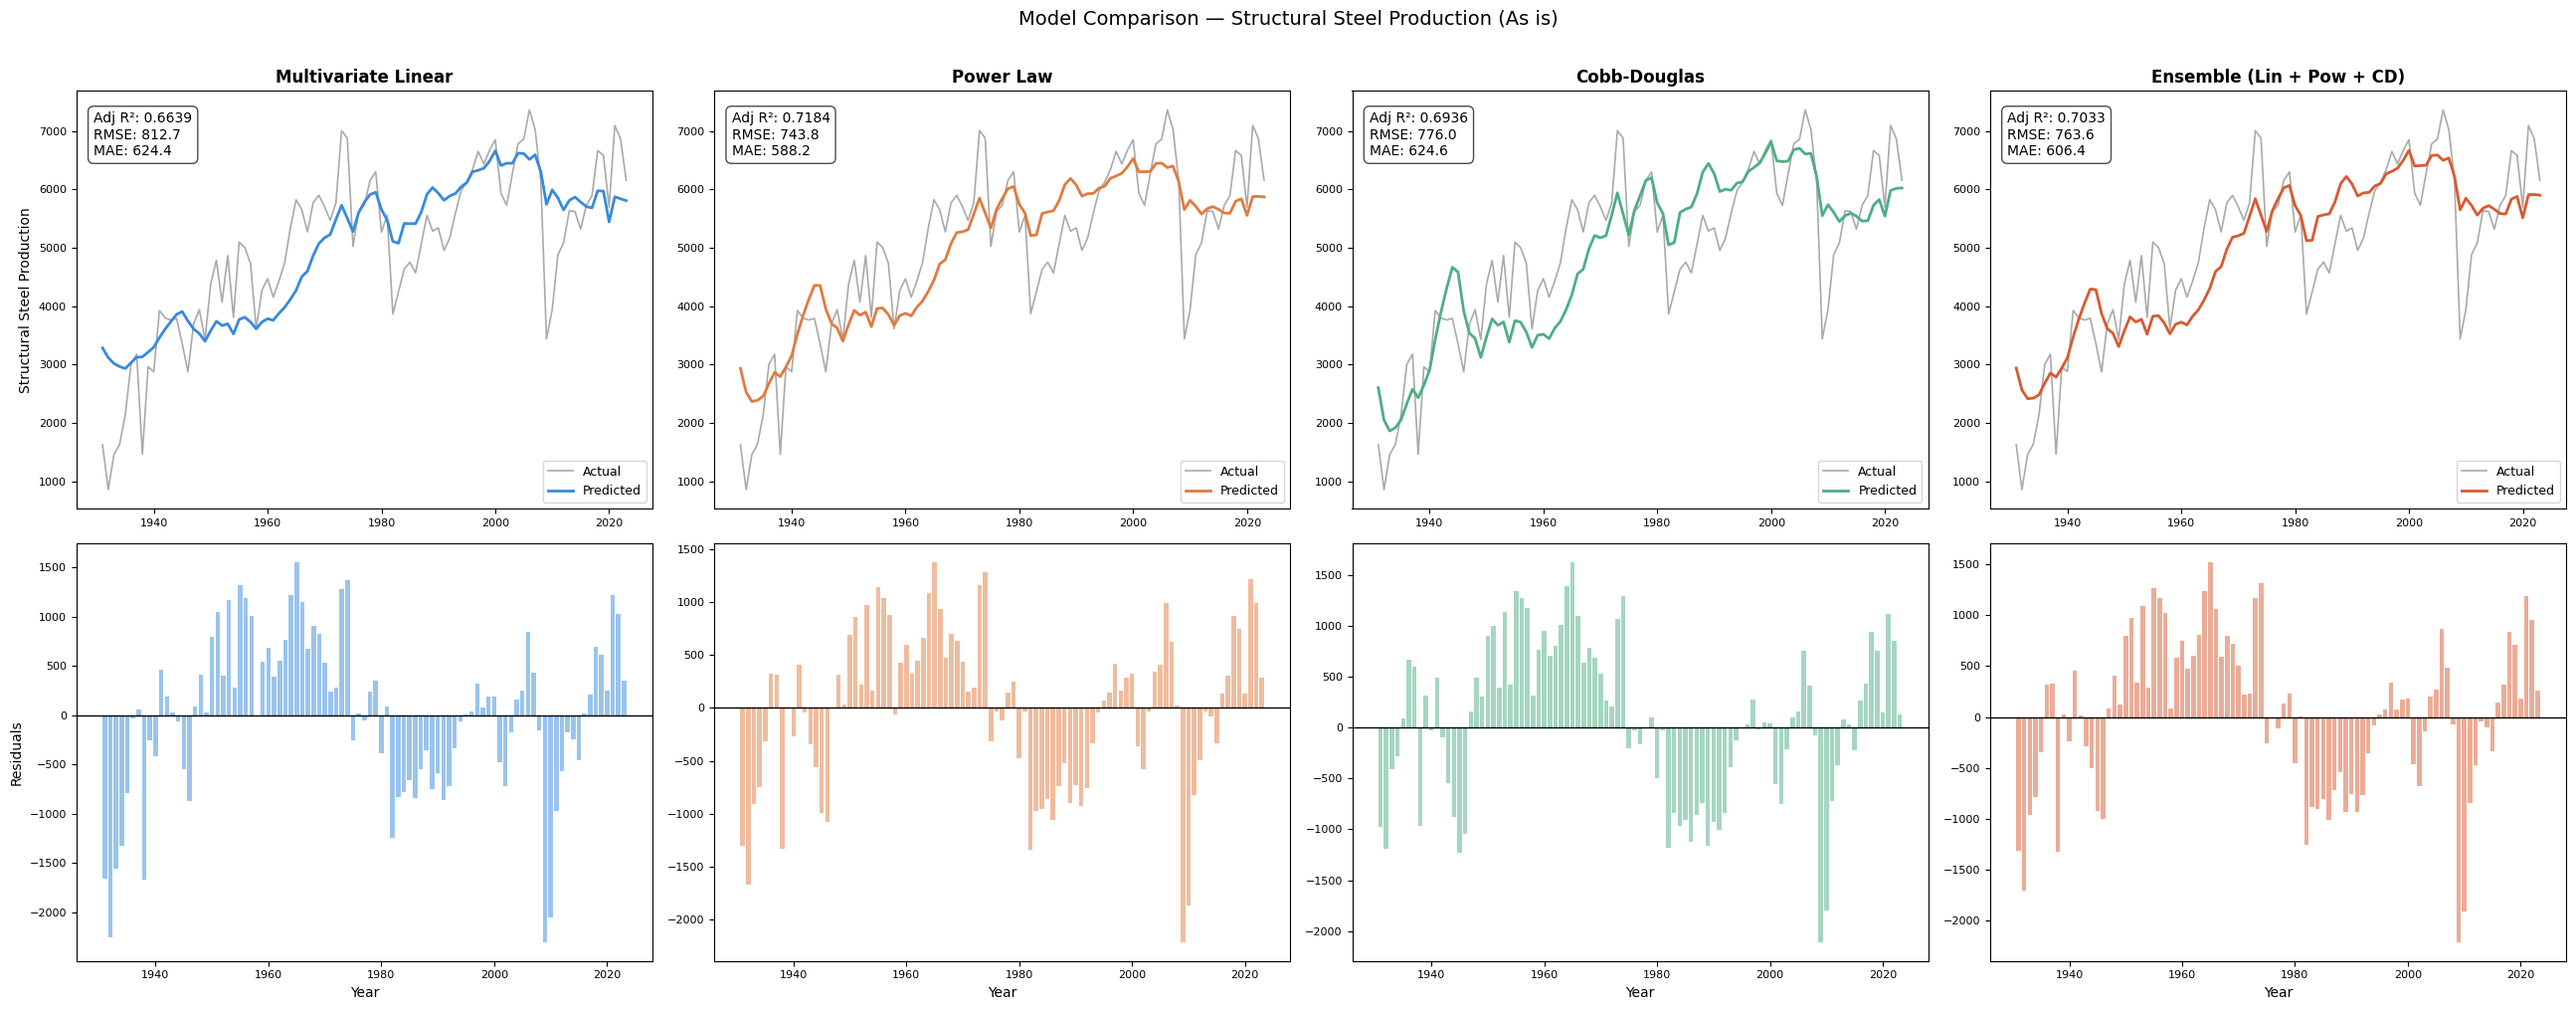

── Fitted parameters (As is) ──

linear:
         intercept: 4,222.91
          pop_ssp2: -2.66726e-05
          gdp_ssp2: 0.0525448
      energy usage: 78.1159

power:
                 a: 24,152.9
       b (pop exp): -1.62252
                 c: -24,704.9
       d (gdp exp): 0.652129
                 e: -12,865.8
    f (energy exp): 0.806202

cobb_douglas:
                 A: 2.06501e+18
       b (pop exp): -2.55395
       d (gdp exp): 1.11155
    f (energy exp): 0.966487


{'linear': {'intercept': np.float64(4222.912349343321),
  'pop_ssp2': np.float64(-2.6672629833827818e-05),
  'gdp_ssp2': np.float64(0.05254476879384487),
  'energy usage': np.float64(78.11592919981156)},
 'power': {'a': np.float64(24152.860029001),
  'b (pop exp)': np.float64(-1.6225192436210762),
  'c': np.float64(-24704.8992753879),
  'd (gdp exp)': np.float64(0.6521288054866468),
  'e': np.float64(-12865.826046507551),
  'f (energy exp)': np.float64(0.8062017447175336)},
 'cobb_douglas': {'A': np.float64(2.0650113073867814e+18),
  'b (pop exp)': np.float64(-2.553946022885457),
  'd (gdp exp)': np.float64(1.1115475095564729),
  'f (energy exp)': np.float64(0.9664866459544301)}}

In [68]:
results["as_is"] = fit_models(df_training, label="As is")
plot_fit(results["as_is"])
print_params(results['as_is'])

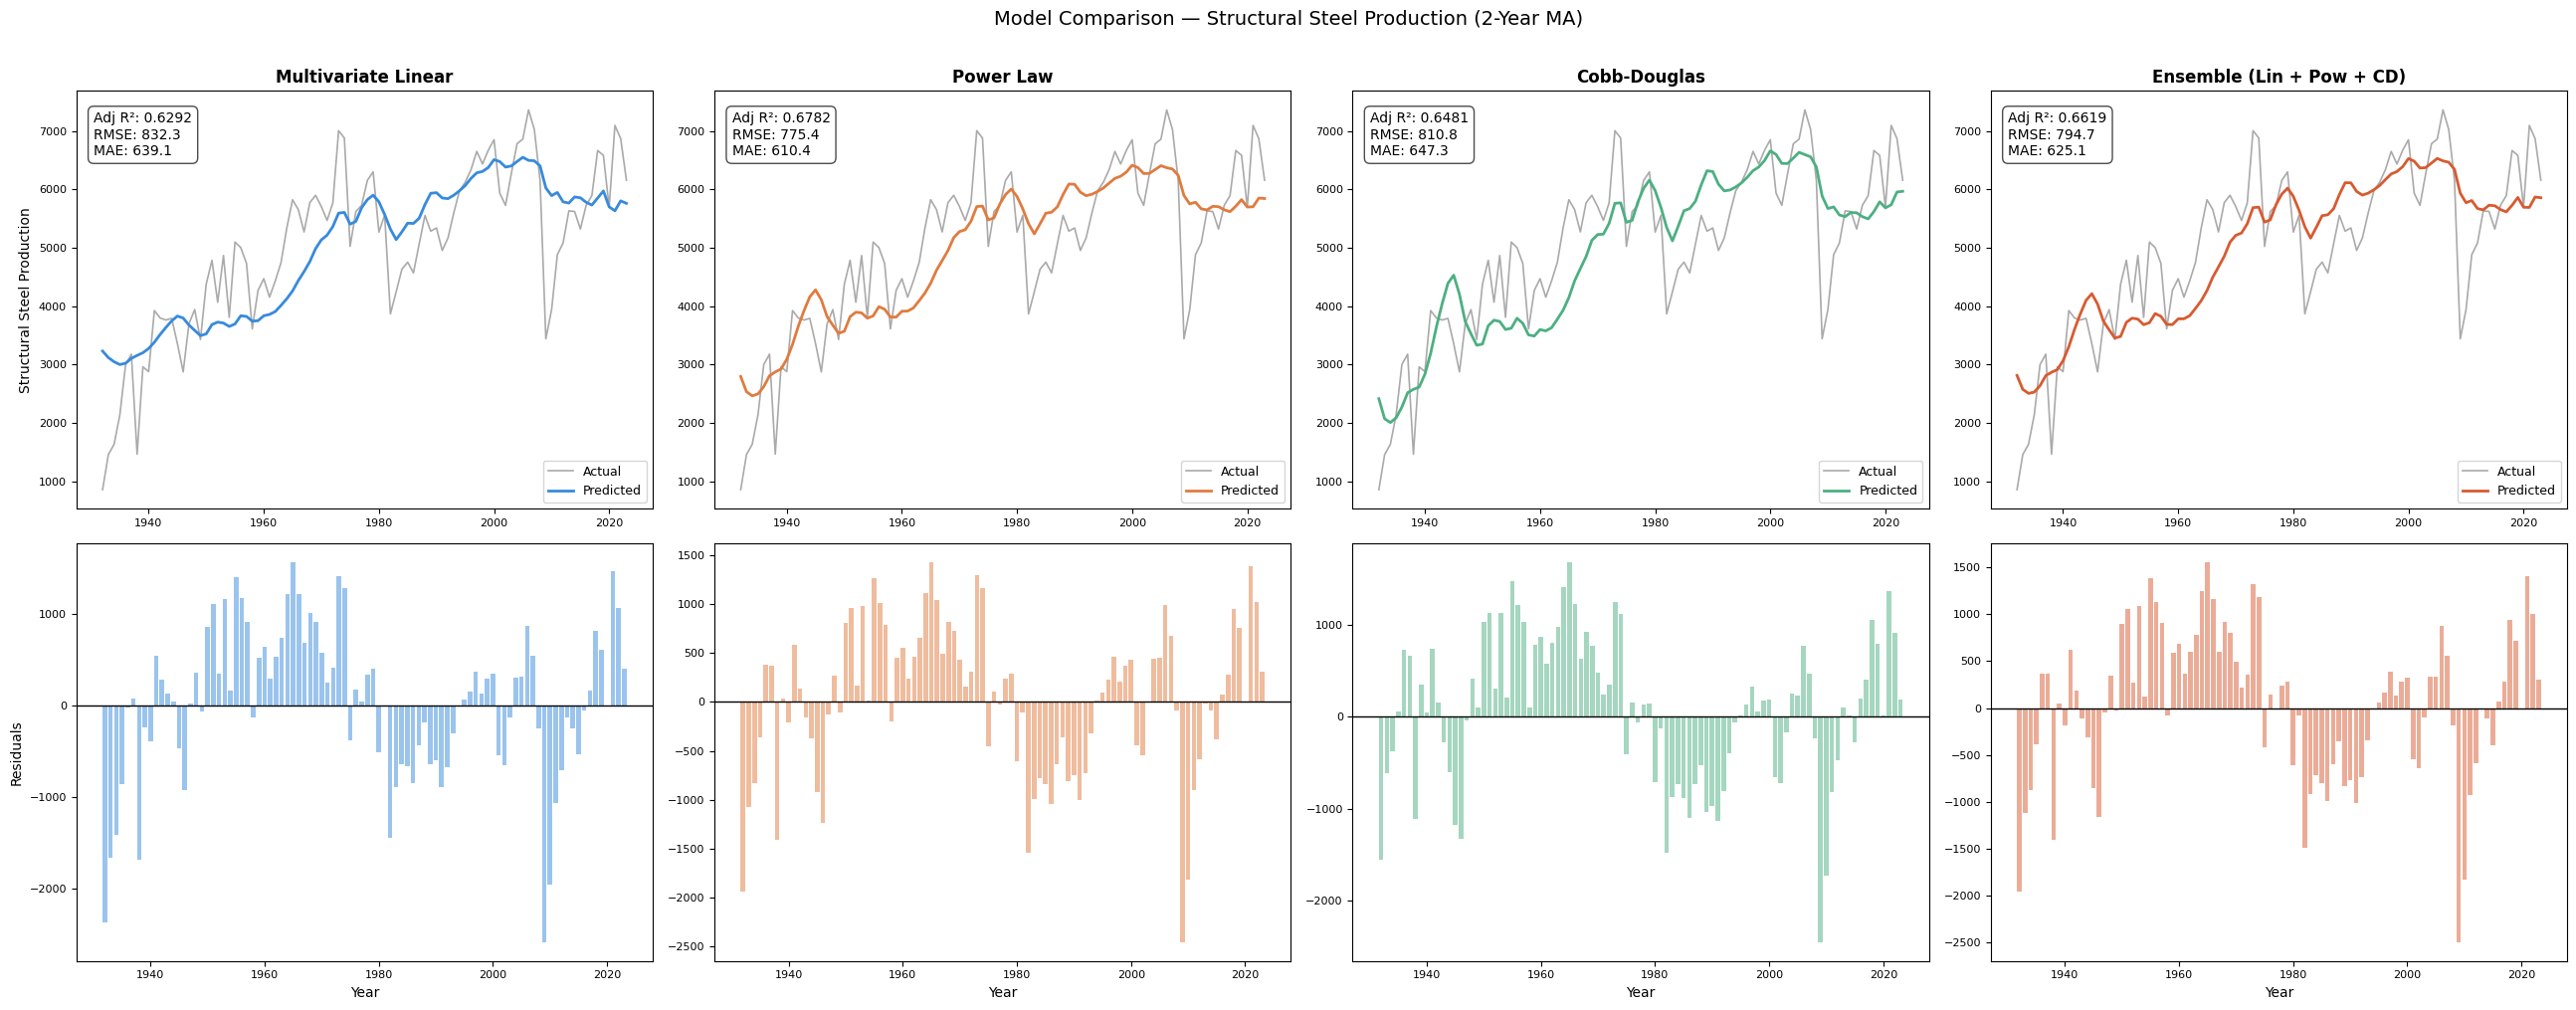

── Fitted parameters (2-Year MA) ──

linear:
         intercept: 3,876.29
          pop_ssp2: -2.17173e-05
          gdp_ssp2: 0.0370517
      energy usage: 73.858

power:
                 a: -11,007.7
       b (pop exp): -1.44693
                 c: 11,192.5
       d (gdp exp): 0.562079
                 e: -5,868.26
    f (energy exp): 0.785455

cobb_douglas:
                 A: 7.49487e+16
       b (pop exp): -2.30323
       d (gdp exp): 0.976515
    f (energy exp): 0.939722


{'linear': {'intercept': np.float64(3876.289181693008),
  'pop_ssp2': np.float64(-2.1717318195800074e-05),
  'gdp_ssp2': np.float64(0.03705166534545454),
  'energy usage': np.float64(73.85798785771112)},
 'power': {'a': np.float64(-11007.69429307405),
  'b (pop exp)': np.float64(-1.4469302999637002),
  'c': np.float64(11192.466322736767),
  'd (gdp exp)': np.float64(0.5620786816525417),
  'e': np.float64(-5868.258497993035),
  'f (energy exp)': np.float64(0.7854550506716611)},
 'cobb_douglas': {'A': np.float64(7.494867524282862e+16),
  'b (pop exp)': np.float64(-2.3032333418103628),
  'd (gdp exp)': np.float64(0.9765146870075819),
  'f (energy exp)': np.float64(0.9397218554044675)}}

In [69]:
results["ma2"] = fit_models(
    df_MA_2, y_actual=df_steel["structural-total"].iloc[1:], label="2-Year MA"
)
plot_fit(results["ma2"])

print_params(results["ma2"])

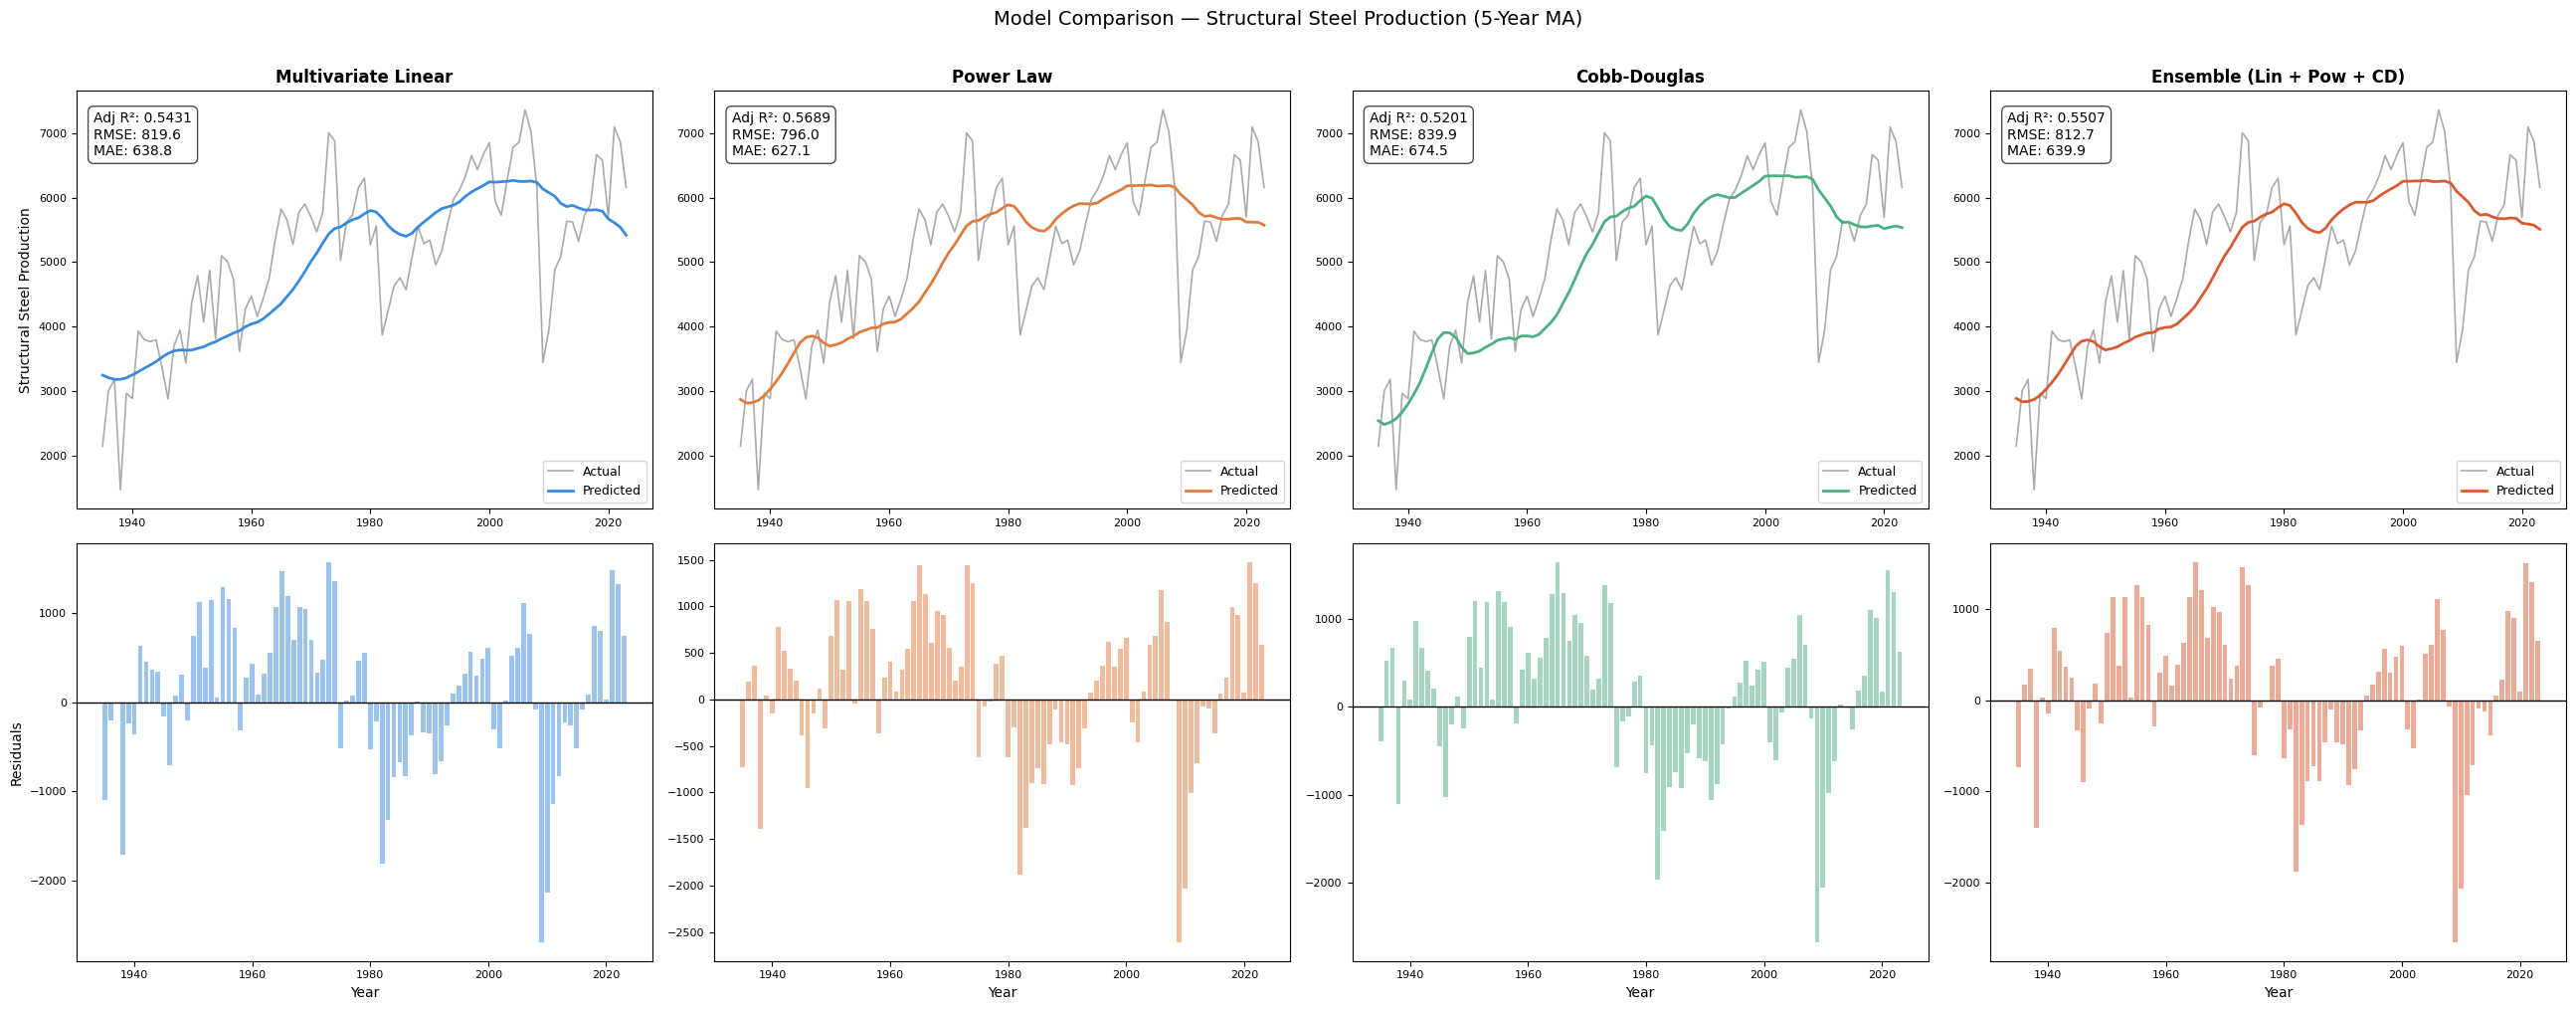

── Fitted parameters (5-Year MA) ──

linear:
         intercept: 2,765.29
          pop_ssp2: -6.17717e-06
          gdp_ssp2: -0.024013
      energy usage: 66.5937

power:
                 a: 880.192
       b (pop exp): -0.858495
                 c: -891.128
       d (gdp exp): 0.183148
                 e: -520.601
    f (energy exp): 0.800686

cobb_douglas:
                 A: 2.77859e+12
       b (pop exp): -1.4912
       d (gdp exp): 0.440055
    f (energy exp): 0.966823


{'linear': {'intercept': np.float64(2765.2913872507565),
  'pop_ssp2': np.float64(-6.177174409470473e-06),
  'gdp_ssp2': np.float64(-0.024012984740936216),
  'energy usage': np.float64(66.59374550854692)},
 'power': {'a': np.float64(880.1919212254377),
  'b (pop exp)': np.float64(-0.8584948771402537),
  'c': np.float64(-891.1280758166621),
  'd (gdp exp)': np.float64(0.18314838803896188),
  'e': np.float64(-520.6008572898911),
  'f (energy exp)': np.float64(0.8006855408791462)},
 'cobb_douglas': {'A': np.float64(2778587896058.8823),
  'b (pop exp)': np.float64(-1.4912019873074303),
  'd (gdp exp)': np.float64(0.44005536843527726),
  'f (energy exp)': np.float64(0.9668228192512898)}}

In [70]:
results["ma5"] = fit_models(
    df_MA_5, y_actual=df_steel["structural-total"].iloc[4:], label="5-Year MA"
)
plot_fit(results["ma5"])

print_params(results["ma5"])

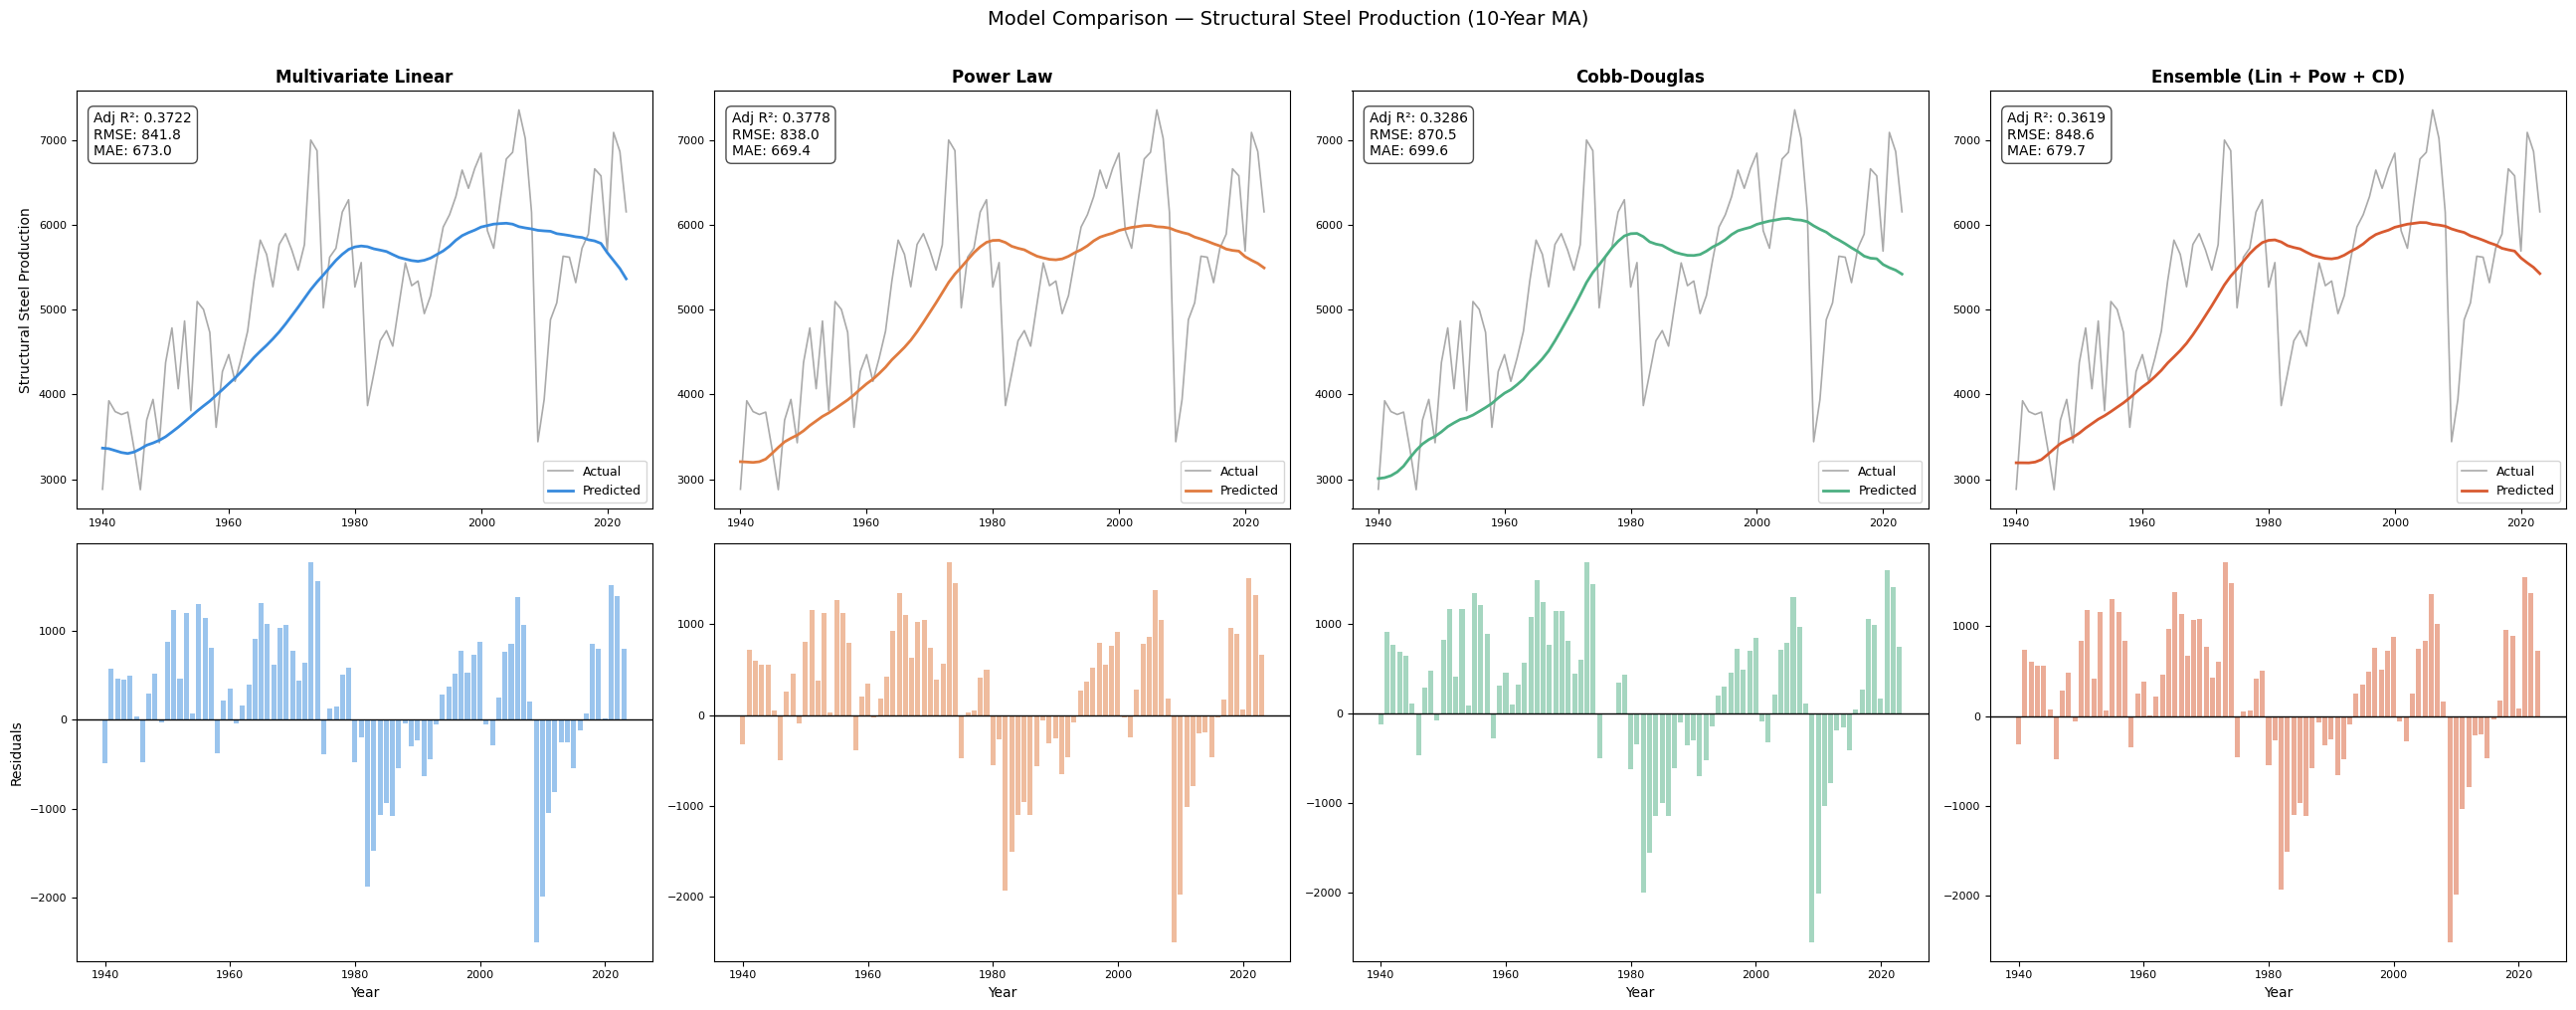

── Fitted parameters (10-Year MA) ──

linear:
         intercept: 1,351.96
          pop_ssp2: 1.36194e-05
          gdp_ssp2: -0.102031
      energy usage: 57.212

power:
                 a: 25.5586
       b (pop exp): -0.0291181
                 c: -25.4845
       d (gdp exp): -0.320384
                 e: -13.7285
    f (energy exp): 0.791182

cobb_douglas:
                 A: 4.19121e+06
       b (pop exp): -0.464681
       d (gdp exp): -0.153113
    f (energy exp): 0.911337


{'linear': {'intercept': np.float64(1351.963169887329),
  'pop_ssp2': np.float64(1.3619417617356666e-05),
  'gdp_ssp2': np.float64(-0.10203096084441872),
  'energy usage': np.float64(57.21196791015244)},
 'power': {'a': np.float64(25.5586251501168),
  'b (pop exp)': np.float64(-0.029118133834276656),
  'c': np.float64(-25.484530219306542),
  'd (gdp exp)': np.float64(-0.3203842554333169),
  'e': np.float64(-13.728521179785718),
  'f (energy exp)': np.float64(0.7911821234046992)},
 'cobb_douglas': {'A': np.float64(4191214.2033413695),
  'b (pop exp)': np.float64(-0.4646808947637734),
  'd (gdp exp)': np.float64(-0.15311250487610006),
  'f (energy exp)': np.float64(0.9113370465889699)}}

In [71]:
results["ma10"] = fit_models(
    df_MA_10, y_actual=df_steel["structural-total"].iloc[9:], label="10-Year MA"
)
plot_fit(results["ma10"])

print_params(results["ma10"])

### Forecast

In [72]:
forecasts = {}

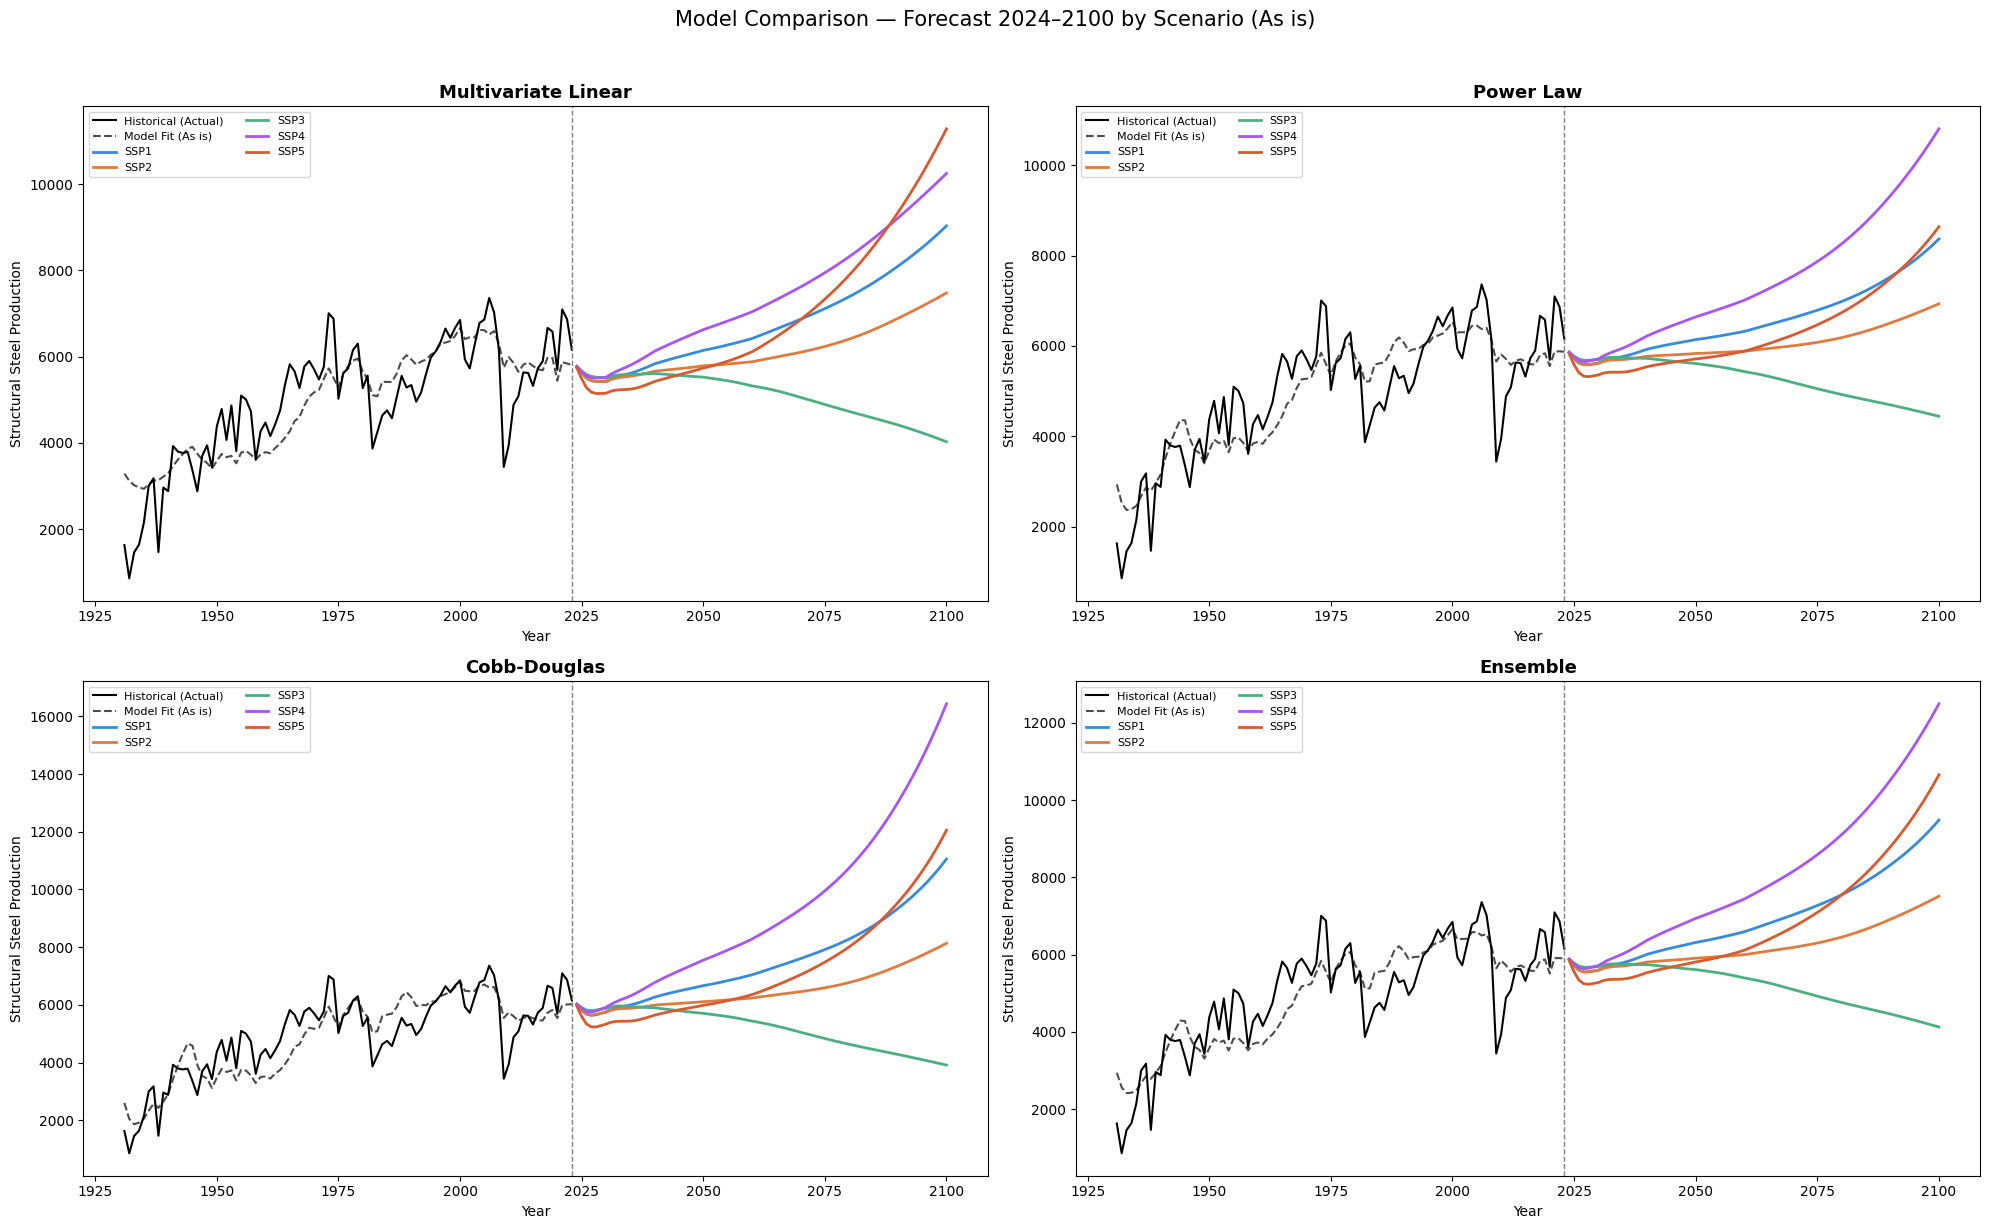

In [73]:
forecasts["as_is"] = forecast_models(results["as_is"], df_population, df_gdp, df_energy_use)
plot_forecast(results["as_is"], forecasts["as_is"])

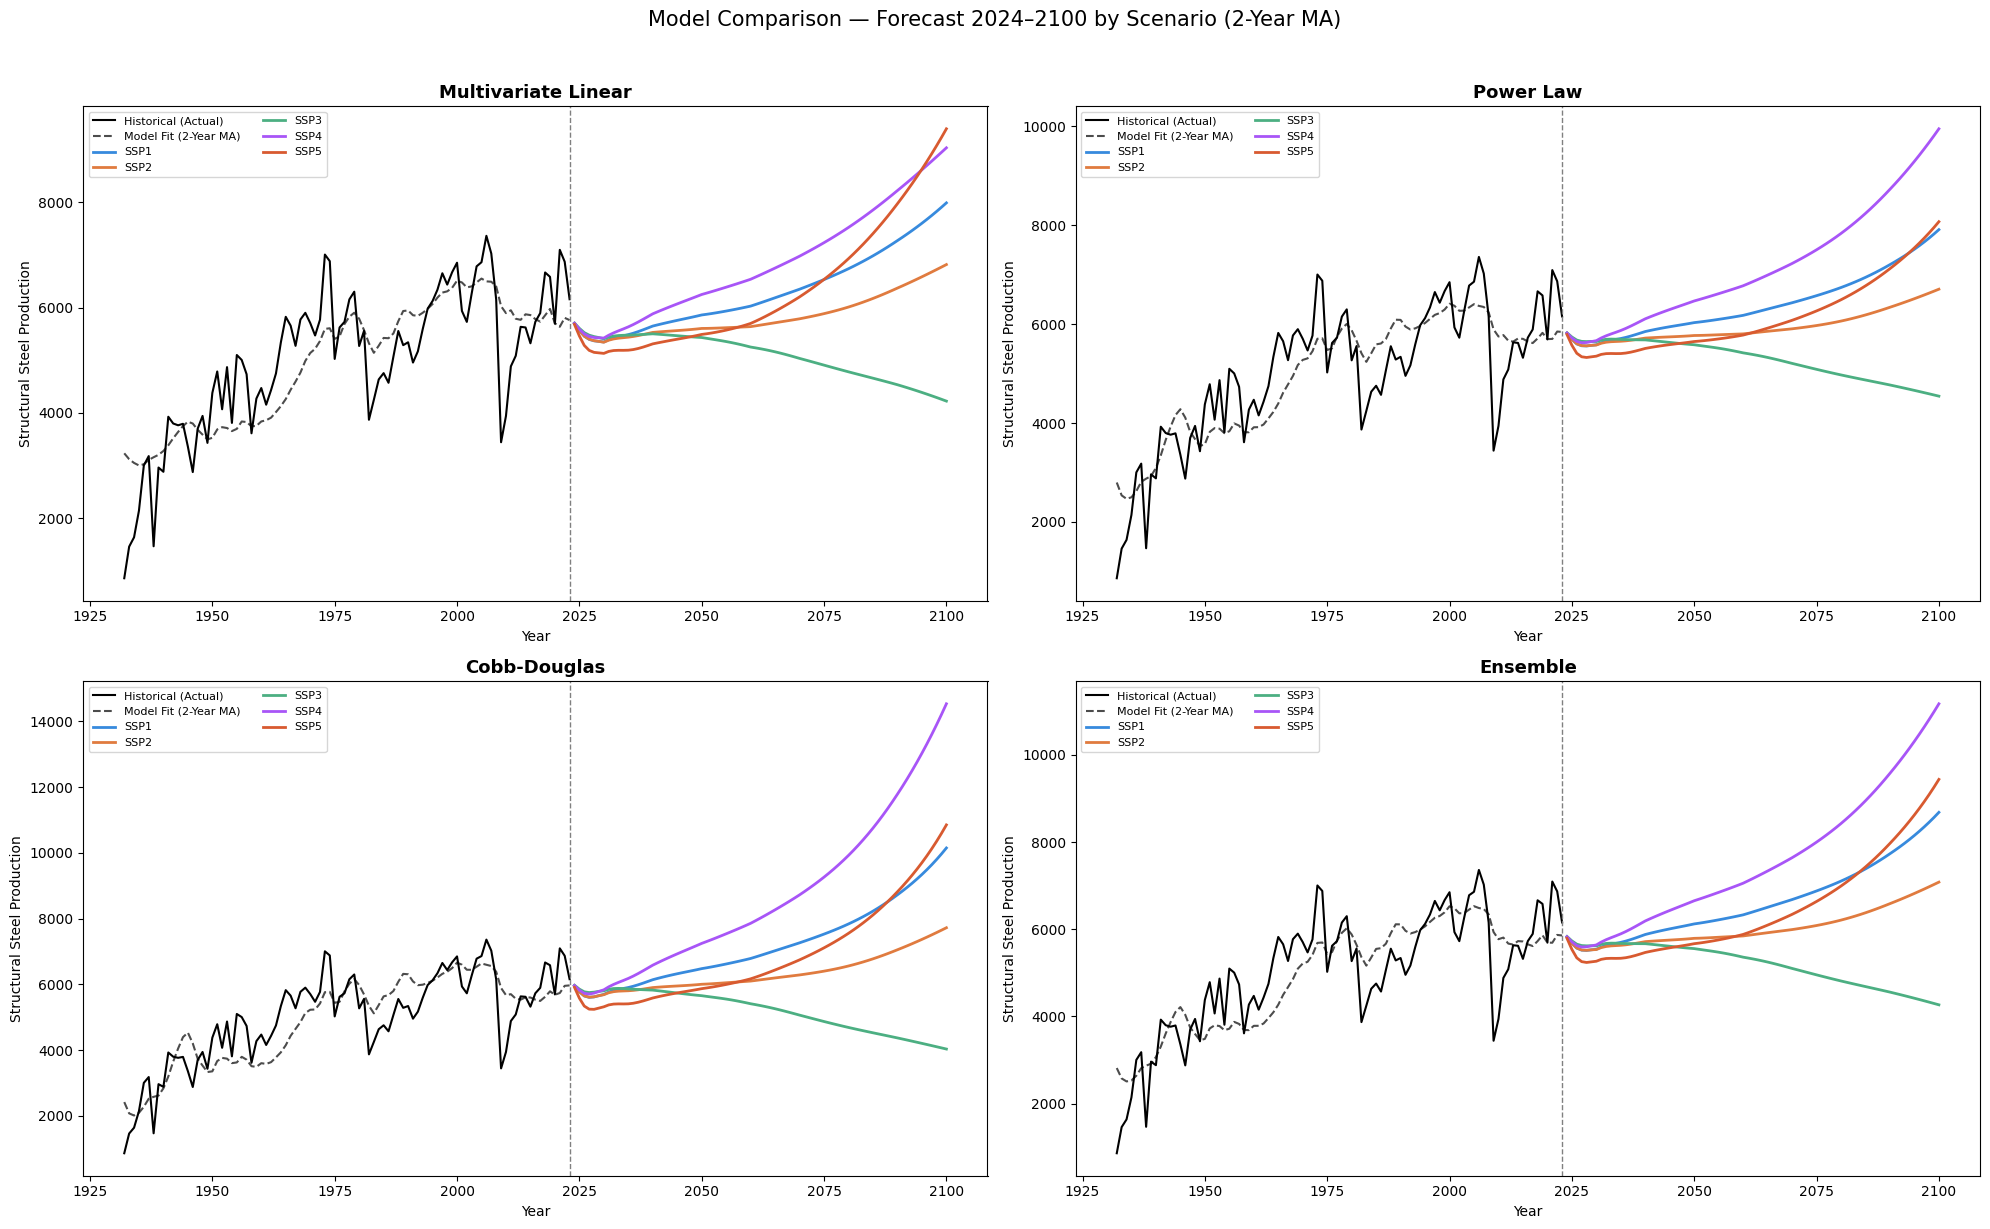

In [74]:
forecasts["ma2"] = forecast_models(results["ma2"], df_population, df_gdp, df_energy_use)
plot_forecast(results["ma2"], forecasts["ma2"])

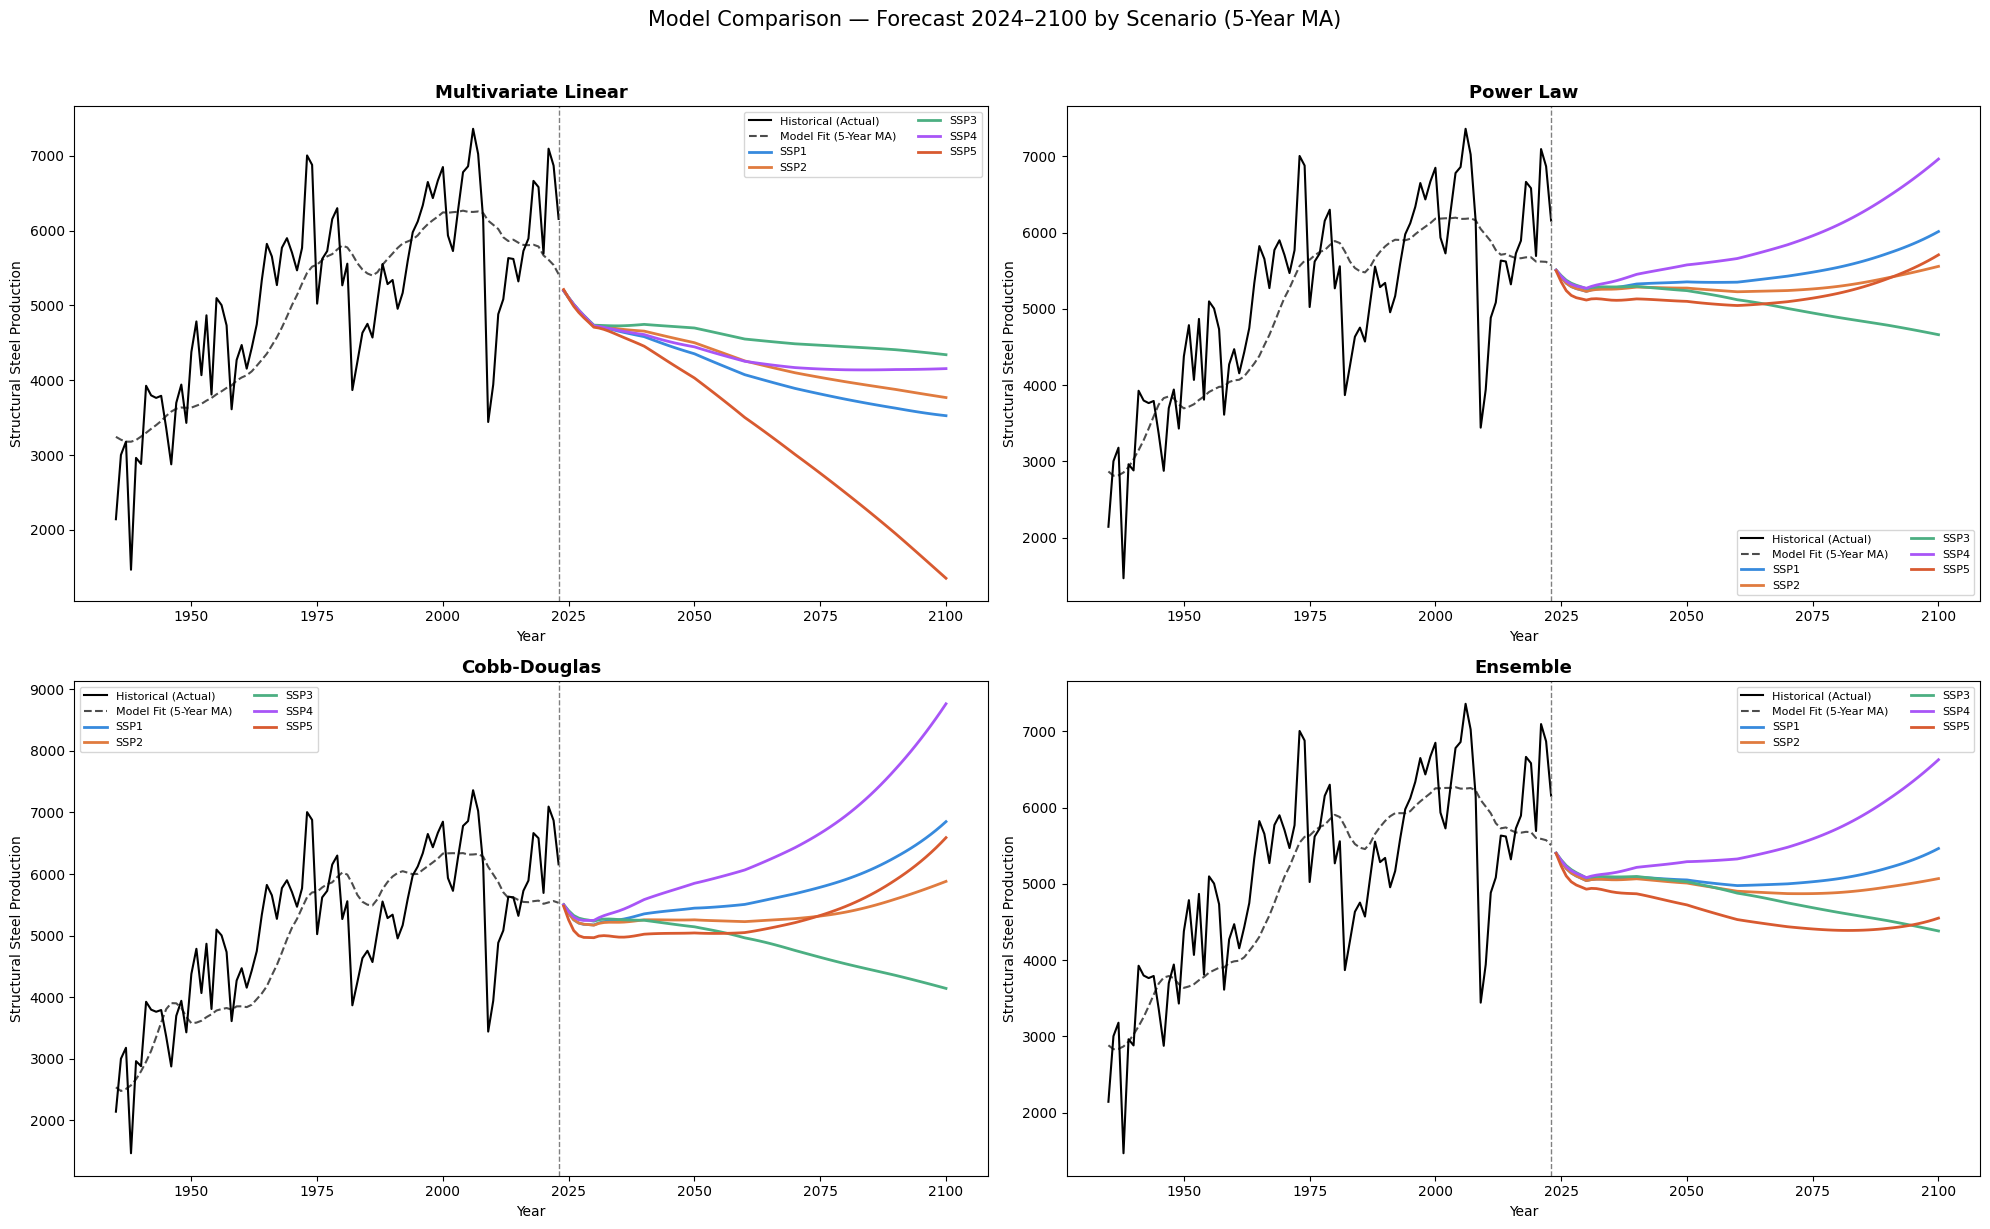

In [75]:
forecasts["ma5"] = forecast_models(results["ma5"], df_population, df_gdp, df_energy_use)
plot_forecast(results["ma5"], forecasts["ma5"])

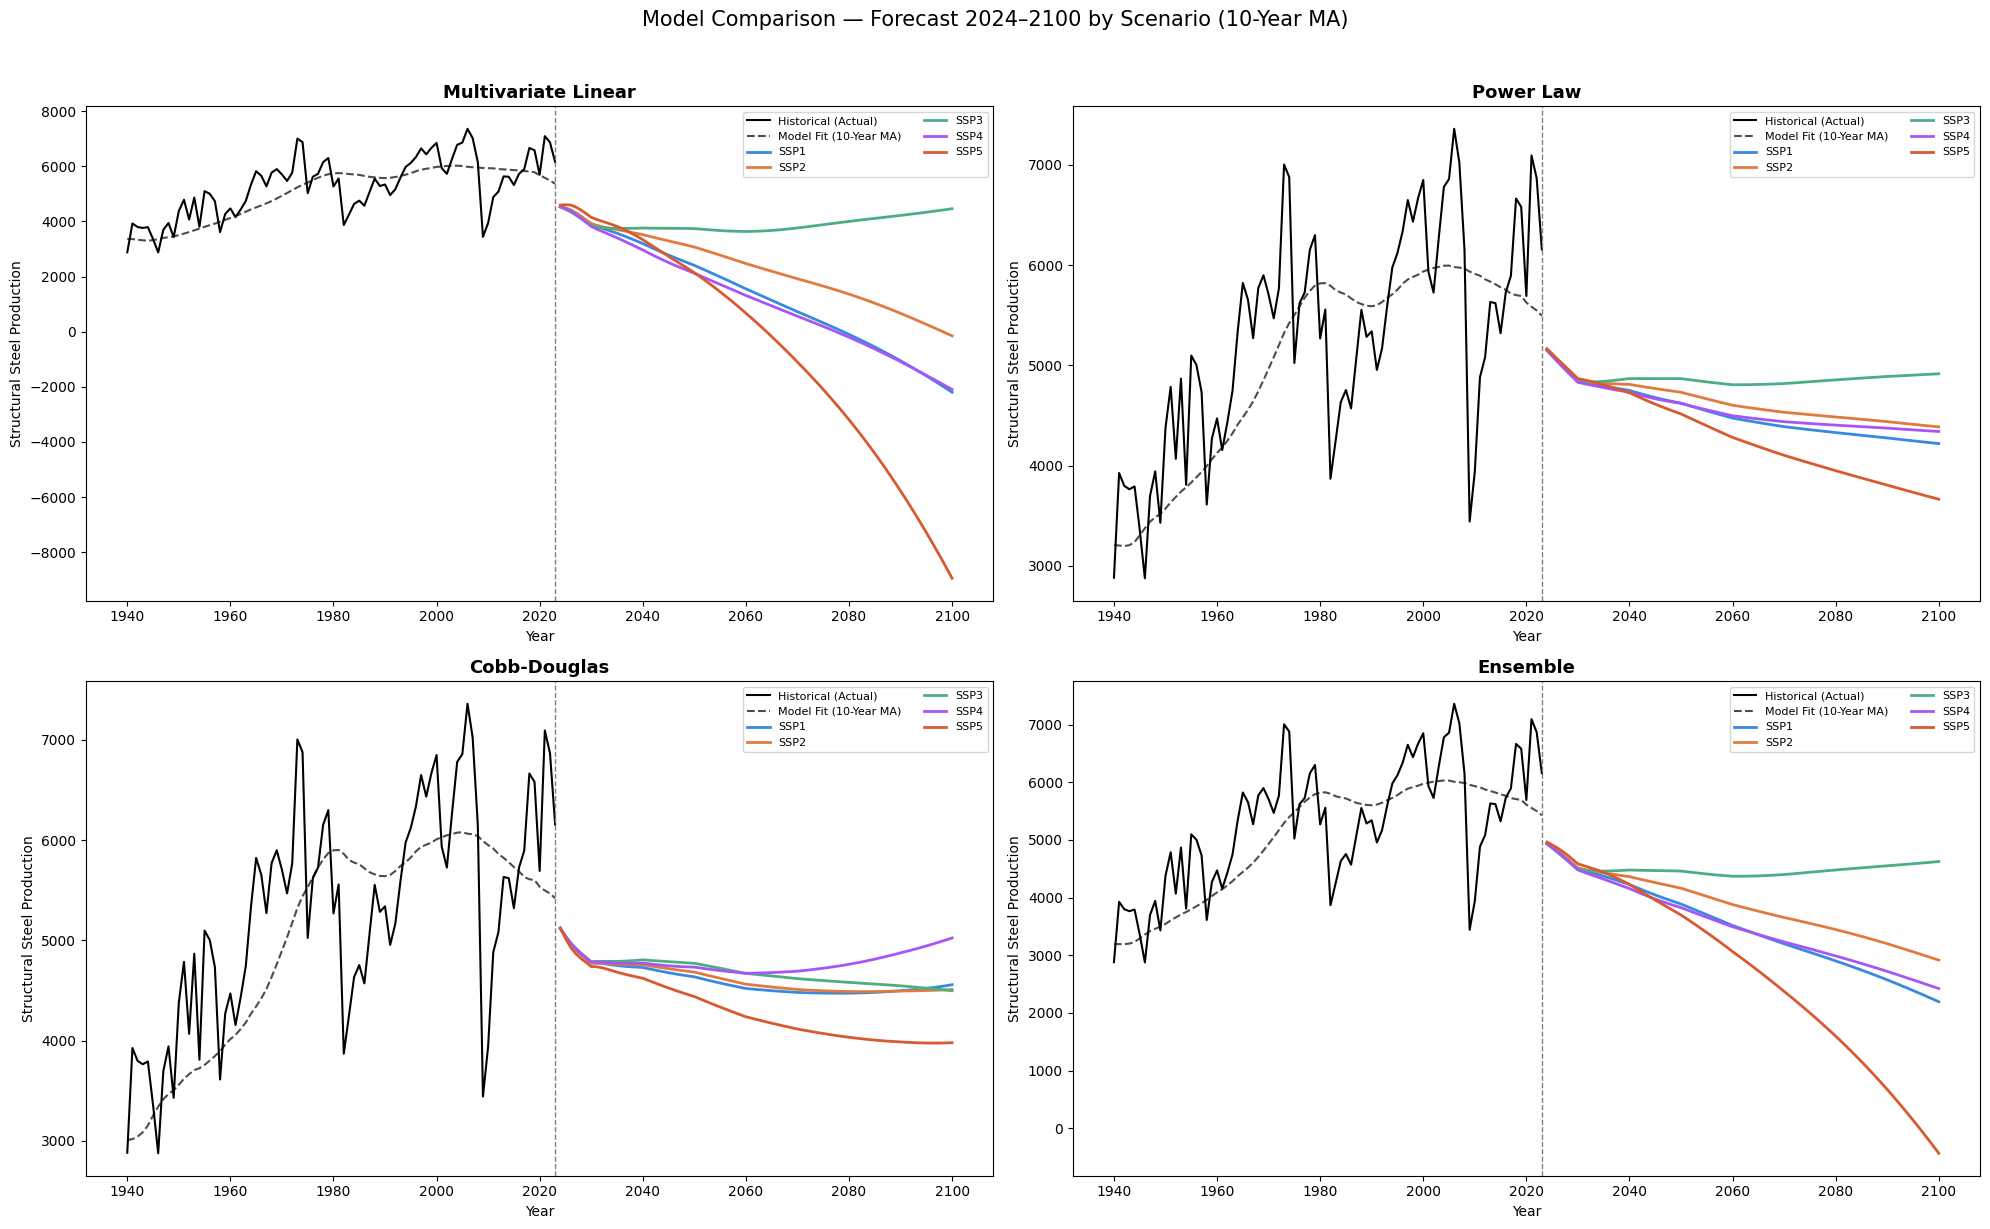

In [76]:
forecasts["ma10"] = forecast_models(results["ma10"], df_population, df_gdp, df_energy_use)
plot_forecast(results["ma10"], forecasts["ma10"])

## Exporting Data

Isolating the 2 Year Moving Average Forecast and combining that with historic data, to be exported and used in validation and Material FLow Analysis

In [80]:
res = results['ma2']
fc = forecast_models(res, df_population, df_gdp, df_energy_use)

scenarios = ["ssp1", "ssp2", "ssp3", "ssp4", "ssp5"]
forecast_pow, _ = fc["Power Law"]

df_hist = pd.DataFrame(
    {s: res['y_actual'] for s in scenarios},
    index=res['idx'],
)


df_fcst = pd.DataFrame(
    {s: forecast_pow[s] for s in scenarios},
    index=fc["forecast_years"],
)

df_power = pd.concat([df_hist, df_fcst])
df_power = df_power/1e3
df_power.index.name = "year"

In [82]:
df_power

,ssp1,ssp2,ssp3,ssp4,ssp5
year,,,,,
1932,0.860000,0.860000,0.860000,0.860000,0.860000
1933,1.460000,1.460000,1.460000,1.460000,1.460000
1934,1.637000,1.637000,1.637000,1.637000,1.637000
1935,2.142000,2.142000,2.142000,2.142000,2.142000
1936,3.002000,3.002000,3.002000,3.002000,3.002000
...,...,...,...,...,...
2096,7.588673,6.553331,4.637745,9.419826,7.641098
2097,7.663736,6.591074,4.614733,9.547424,7.741601
2098,7.742694,6.629498,4.591481,9.678808,7.847008


In [81]:
df_power.to_csv(BASE_DIR / "output_data/steel_forecast.csv")